In [136]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
import matplotlib.pyplot as plt

In [126]:
df= pd.read_pickle("../data/jan_2025_1.pickle")
# df= pd.read_pickle("../data/keep/uniform_sparse_cs_Nov_2024.pickle")

print(df.columns)

Index(['sqt_n', 'm', 'sigma', 'lambda_', 'tol', 'max_iter', 'img',
       'sampling_type', 'adapted_sampling', 'seed', 're', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr', 'optim_info'],
      dtype='object')


In [127]:
df.columns

Index(['sqt_n', 'm', 'sigma', 'lambda_', 'tol', 'max_iter', 'img',
       'sampling_type', 'adapted_sampling', 'seed', 're', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr', 'optim_info'],
      dtype='object')

In [128]:
df_vals(df)

'sqt_n':
[400]
----------------------------------------
'm':
[   100    350   1223   4278  14961  52324 182995 640000]
----------------------------------------
'sigma':
[ 0.   0.1 10. ]
----------------------------------------
'lambda_':
[1.e-03 1.e-05 1.e-07]
----------------------------------------
'tol':
[1.e-10]
----------------------------------------
'max_iter':
[1000000.]
----------------------------------------
'img':
Categorical:  ['phantom', 'camera']
Categories (2, object): ['camera', 'phantom']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'seed':
min: 26665356.00, max: 4273310224.00, mean: 2167528047.10, std: 1268192411.72
----------------------------------------
're':
min: 0.02, max: 1.06, mean: 0.37, std: 0.39
----------------------------------------
'runtime_seconds':
min: 28.21, max: 604.39,

/opt/homebrew/anaconda3/envs/torch/lib/python3.12/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


In [129]:
df_wr = df[df['sampling_type']=='wr']
mydf = df_wr[df_wr['adapted_sampling']==True]

In [130]:
mydf['prop_m'] = mydf['m']/mydf['sqt_n']**2

In [138]:
mydf['unique_meas'] = mydf['indices'].apply(lambda x: len(np.unique(x)))/ mydf['sqt_n']**2

In [140]:
mydf['unique_meas'].dtype

dtype('float64')

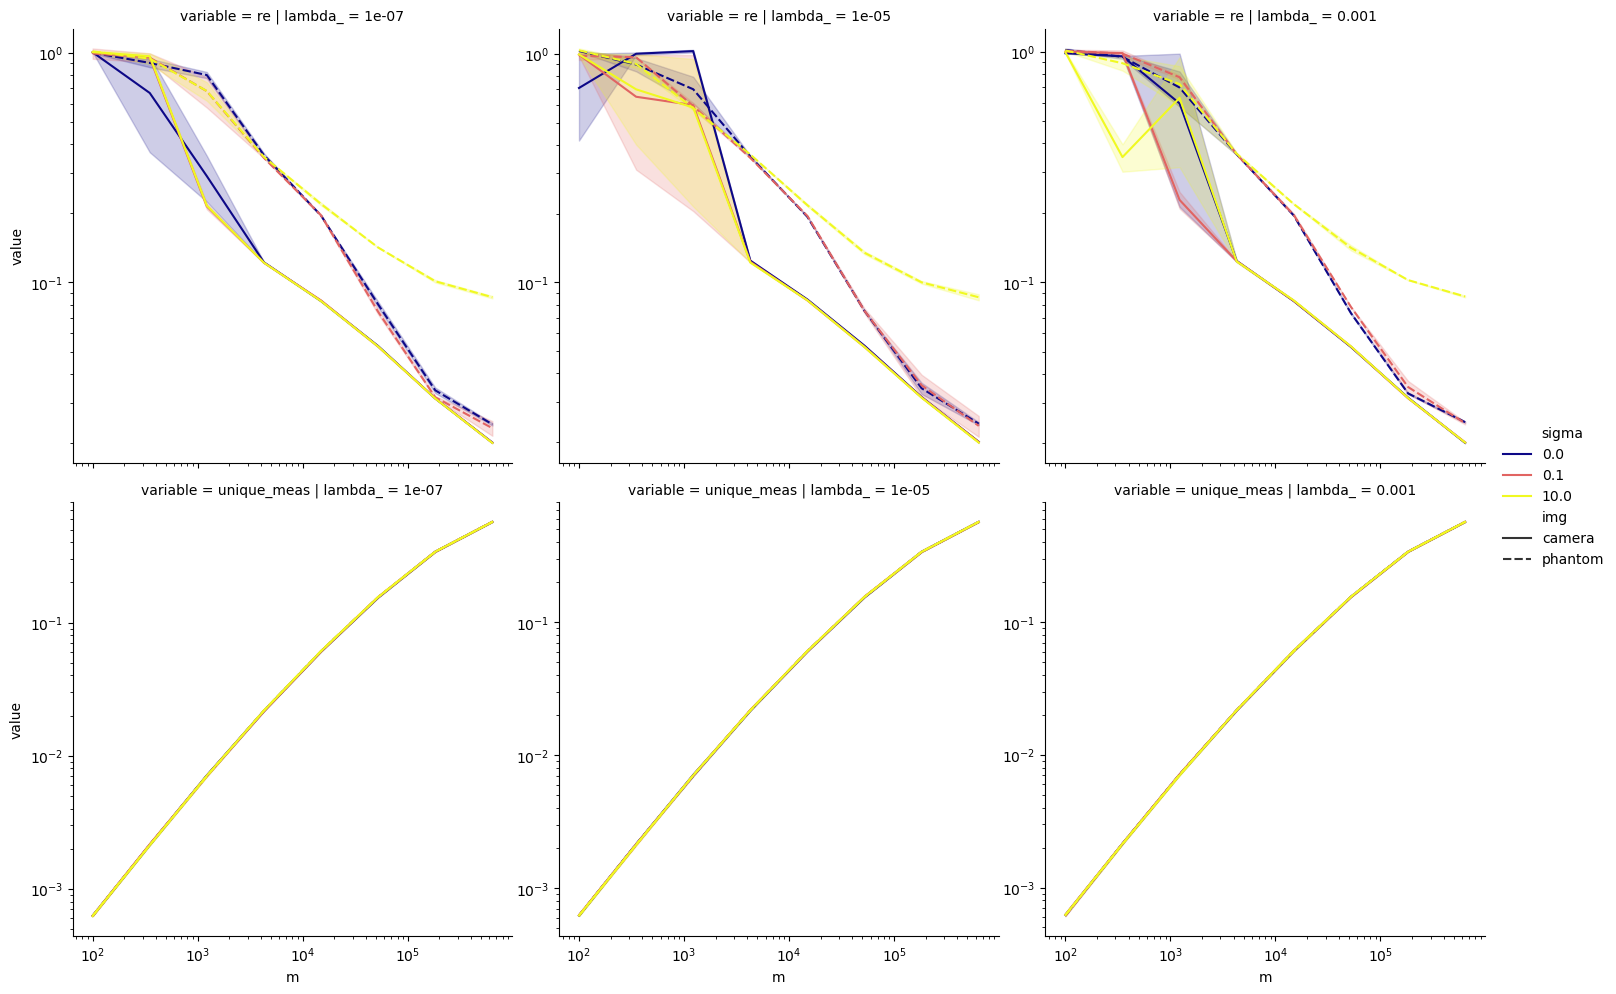

In [150]:
doubledf=melt_and_keep(mydf, ["re","unique_meas"])
#sns.relplot(mydf, kind = "line", x = "m", y="re", col="lambda_", style="img", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
g=sns.relplot(doubledf, kind = "line", x = "m", y="value", row="variable", col="lambda_", style="img", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

In [134]:
df_wr

,sqt_n,m,sigma,lambda_,tol,max_iter,img,sampling_type,adapted_sampling,seed,re,runtime_seconds,indices,experiment_fn_label,m_tld,emp_snr,optim_info
0,400,100,0.0,1.000000e-03,1.000000e-10,1000000.0,phantom,wr,True,822569775,1.032216,108.954146,"[152742, 2013, 8, 157197, 10779, 6384, 123093,...",fully_sparse_exp,100,inf,{'resid': [(-0.004698809637434742-0.0017120890...
1,400,100,0.0,1.000000e-03,1.000000e-10,1000000.0,camera,wr,True,2137449171,0.980242,116.015889,"[25123, 158011, 4337, 156008, 149240, 159229, ...",fully_sparse_exp,100,inf,{'resid': [(-0.030263287300215325+0.0054710369...
2,400,100,0.0,1.000000e-05,1.000000e-10,1000000.0,phantom,wr,True,2671936806,1.022624,116.692582,"[157200, 2799, 142844, 1581, 116764, 3992, 100...",fully_sparse_exp,100,inf,{'resid': [(-0.0011192077360249186-0.000367821...
3,400,100,0.0,1.000000e-05,1.000000e-10,1000000.0,camera,wr,True,3512589365,1.000120,98.191865,"[7175, 145696, 3191, 141108, 6809, 4410, 15256...",fully_sparse_exp,100,inf,{'resid': [(-0.06870520462449292-0.18639745270...
4,400,100,0.0,1.000000e-07,1.000000e-10,1000000.0,phantom,wr,True,1880026316,1.004004,101.140368,"[157198, 9986, 4414, 158795, 2398, 3235, 36801...",fully_sparse_exp,100,inf,{'resid': [(-0.00023377430987636671-4.30612380...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,400,640000,10.0,1.000000e-03,1.000000e-10,1000000.0,camera,wr,True,2825097111,0.020079,176.870547,"[5178, 4002, 35544, 105954, 159592, 16861, 157...",fully_sparse_exp,640000,7.348660e+04,{'resid': [(0.010083686736486186-0.00416431352...
284,400,640000,10.0,1.000000e-05,1.000000e-10,1000000.0,phantom,wr,True,4197219970,0.083539,79.704083,"[7602, 98430, 132777, 3588, 402, 107528, 10011...",fully_sparse_exp,640000,9.211124e+01,{'resid': [(0.017412174058553553-1.65705177357...
285,400,640000,10.0,1.000000e-05,1.000000e-10,1000000.0,camera,wr,True,2430515944,0.019841,171.929488,"[154803, 157185, 155601, 159247, 157208, 400, ...",fully_sparse_exp,640000,7.307200e+04,{'resid': [(0.04157495612385986+0.000356743920...
286,400,640000,10.0,1.000000e-07,1.000000e-10,1000000.0,phantom,wr,True,2391844417,0.087267,88.420178,"[43192, 16, 156550, 117279, 7685, 152383, 1279...",fully_sparse_exp,640000,9.276000e+01,{'resid': [(0.010594724434228334+6.16953882079...
